# 모멘텀과 Adam 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week09/momentum_adam/lab/momentum_adam.ipynb)

길쭉한 골짜기에서 경사하강법 · 모멘텀 · Adam 을 직접 구현해 걸음 수를 비교한다.

- **파트 1**: 세 방법 직접 구현 → 111 · 33 · 27걸음
- **파트 2**: 학습률을 바꿔 가며 각자 가장 좋은 학습률 찾기
- **파트 3**: 실제 신경망 (손글씨 숫자) 에서 `torch.optim`

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## 파트 1. 골짜기 $f(x, y) = \frac12(x^2 + 50y^2)$

시작 (−4, 1.5). 바닥 (0, 0) 에서 0.05 안에 들어오면 도착.

In [ ]:
def grad(p):
    return np.array([p[0], 50 * p[1]])

def run(method, lr, start=(-4.0, 1.5), max_steps=2000, beta=0.9, b1=0.9, b2=0.999, eps=1e-8):
    p = np.array(start); v = np.zeros(2); m = np.zeros(2); s = np.zeros(2); path = [p.copy()]
    for t in range(1, max_steps + 1):
        g = grad(p)
        if method == "gd":
            p = p - lr * g
        elif method == "momentum":
            v = None  # TODO: remember the velocity
            p = p - lr * v
        elif method == "adam":
            m = b1 * m + (1 - b1) * g
            s = None  # TODO: running mean of squared gradients
            m_hat, s_hat = m / (1 - b1 ** t), s / (1 - b2 ** t)
            p = p - lr * m_hat / (np.sqrt(s_hat) + eps)
        path.append(p.copy())
        if np.linalg.norm(p) < 0.05:
            return t, np.array(path)
    return None, np.array(path)

xs, ys = np.meshgrid(np.linspace(-4.5, 1.5, 200), np.linspace(-1.8, 1.8, 150))
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (method, lr) in zip(axs, [("gd", 0.039), ("momentum", 0.007), ("adam", 0.18)]):
    steps, path = run(method, lr)
    ax.contour(xs, ys, (xs ** 2 + 50 * ys ** 2) / 2, levels=np.geomspace(0.05, 80, 12), colors="gray", linewidths=0.6)
    ax.plot(path[:, 0], path[:, 1], "o-", ms=2); ax.set_title(f"{method}: {steps} steps")
    print(f"{method:8s} lr={lr}: {steps} steps")
plt.show()

**예상 결과**

```
gd       lr=0.039: 111 steps
momentum lr=0.007: 33 steps
adam     lr=0.18: 27 steps
```

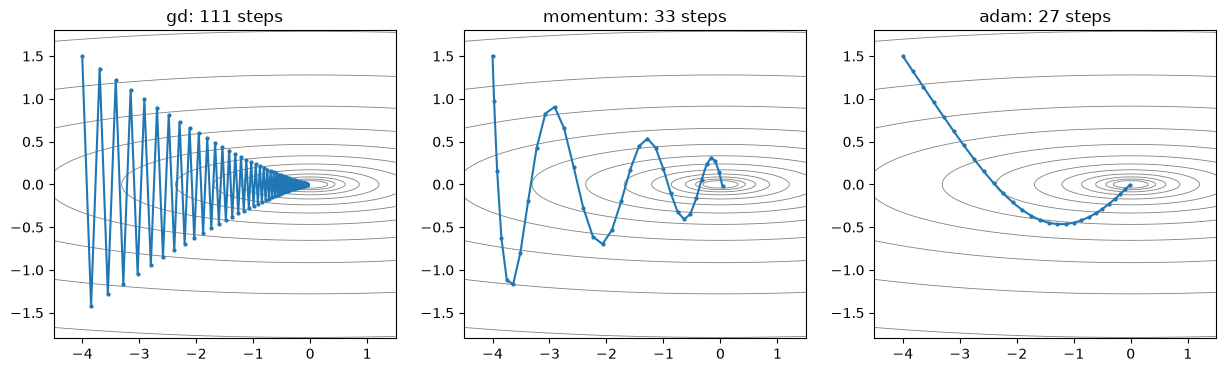

## 파트 2. 가장 좋은 학습률 찾기

슬라이드는 쇼츠와 같은 격자 (Adam 0.18 → 27걸음). 여기서는 격자를 더 촘촘히 훑는다.

In [ ]:
for method, grid in [("gd", np.round(np.arange(0.005, 0.045, 0.001), 3)),
                     ("momentum", np.round(np.arange(0.001, 0.03, 0.001), 3)),
                     ("adam", np.round(np.arange(0.01, 0.5, 0.01), 2))]:
    results = {lr: run(method, lr)[0] for lr in grid}
    ok = {lr: s for lr, s in results.items() if s is not None}
    best = None  # TODO: the learning rate with the fewest steps
    print(f"{method:8s}: best lr {best} -> {ok[best]} steps   (lr {grid[-1]}: {results[grid[-1]]})")

**예상 결과**

```
gd      : best lr 0.039 -> 111 steps   (lr 0.044: None)
momentum: best lr 0.007 -> 33 steps   (lr 0.029: 48)
adam    : best lr 0.19 -> 26 steps   (lr 0.49: 58)
```

## 파트 3. 실제 신경망

손글씨 숫자 1,797장, 은닉층 2개. 같은 조건에서 옵티마이저만 바꾼다.

In [ ]:
import torch, torch.nn as nn
from sklearn.datasets import load_digits
d = load_digits(); X = torch.tensor(d.data / 16., dtype=torch.float32); y = torch.tensor(d.target)

def train(make_opt, epochs=30):
    torch.manual_seed(0)
    net = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))
    opt = make_opt(net.parameters()); g = torch.Generator().manual_seed(0); losses = []
    for _ in range(epochs):
        for b in torch.randperm(len(y), generator=g).split(64):
            opt.zero_grad(); nn.functional.cross_entropy(net(X[b]), y[b]).backward(); opt.step()
        with torch.no_grad():
            losses.append(nn.functional.cross_entropy(net(X), y).item())
    return losses

opts = {"SGD": lambda p: torch.optim.SGD(p, lr=0.05),
        "momentum": lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9),
        opts = {"SGD": lambda p: torch.optim.SGD(p, lr=0.05), "momentum": None, "Adam": None}  # TODO: momentum 0.9 and Adam (default lr)
for name, make in opts.items():
    L = train(make)
    plt.semilogy(range(1, 31), L, label=name)
    print(f"{name:8s}: loss after 10 epochs {L[9]:.3f}")
plt.xlabel("epoch"); plt.ylabel("training loss"); plt.legend(); plt.show()

**예상 결과**

```
SGD     : loss after 10 epochs 0.817
momentum: loss after 10 epochs 0.066
Adam    : loss after 10 epochs 0.186
```

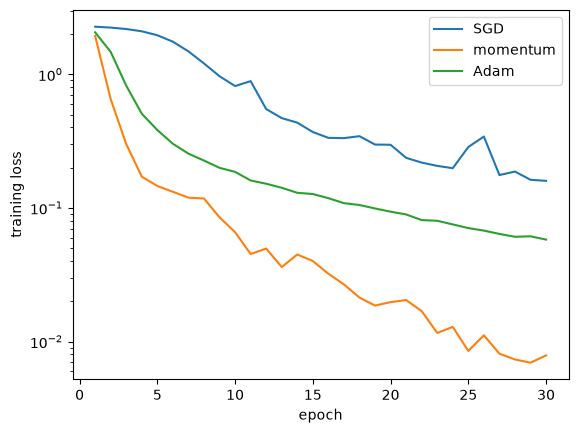

**확인 질문**
1. 파트 1 에서 경사하강법의 학습률을 0.041 로 하면? 왜 그런가?
2. 파트 1 의 모멘텀에서 β 를 0.5, 0.99 로 바꾸면 걸음 수와 경로가 어떻게 달라지나?
3. 파트 2 에서 Adam 은 학습률이 크게 바뀌어도 도착하는 편인가? 경사하강법과 비교하자.
4. 파트 3 에서 Adam 의 학습률을 0.01 로 키우면 어떻게 되나?

데이터 출처: Alpaydin & Kaynak, Optical Recognition of Handwritten Digits (scikit-learn `load_digits`) · Kingma & Ba (2014) arXiv:1412.6980.